# Basics 2: QC, normalisation and embedding

The second of three notebooks that together run or name every public function:

1. [Reading and preparing data](basics_1_data.ipynb)
2. **QC, normalisation and embedding** (this notebook): filter cells, perturbations and genes; per-cell metrics, outliers and doublets; subsample; normalise; select variable genes; PCA, neighbours, UMAP, clusters and their markers; gene-set and cell-cycle scores.
3. [Effects and differential expression](basics_3_effects_tests.ipynb)

It runs on its own, on the bundled `data/Adamson_subset.h5ad` (1,716 cells, 11,630 genes, two targets and a control), in under a minute. Every step streams the matrix from disk and writes its result to a file; the table at the end lists the functions of this area.

In [1]:
import os

# Progress bars off, so the saved notebook keeps only crispyx's summary lines; tqdm
# reads this when first imported, so it is set before anything imports tqdm.
os.environ.setdefault('TQDM_DISABLE', '1')

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
DATA_PATH = ROOT / 'data' / 'Adamson_subset.h5ad'
OUTPUT_DIR = Path('tutorial_outputs') / 'basics_qc'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='IProgress not found')

import crispyx as cx
print(f'crispyx {cx.__version__}')

crispyx 0.2.13


## 1. Quality control

QC keeps cells with enough detected genes, perturbations with enough cells, and genes seen in enough cells. Each filter is a function that returns a boolean mask; a later filter takes the earlier mask, so it counts only the cells still kept.

In [2]:
cell_mask = cx.pp.filter_cells(DATA_PATH, min_genes=1000)
cell_mask = cx.pp.filter_perturbations(DATA_PATH, perturbation_column='perturbation', min_cells=50, base_mask=cell_mask)
gene_mask = cx.pp.filter_genes(DATA_PATH, min_cells=100, cell_mask=cell_mask)

[cx] pp.filter_cells: Done  1715/1716 cells kept (100%)
[cx] resolve_control_label: Inferred control label 'control'
[cx] pp.filter_perturbations: Done  3/3 perturbations kept (100%)
[cx] pp.filter_genes: Done  9238/11630 genes kept (79%)


`cx.pp.qc_summary` applies the three in one call and writes the filtered file. `cx.quality_control_summary`, used here, is the same call returning the masks and the per-cell and per-gene counts as well, which the QC plots take.

In [3]:
qc = cx.quality_control_summary(
    DATA_PATH, perturbation_column='perturbation',
    min_genes=1000, min_cells_per_perturbation=50, min_cells_per_gene=100,
    output_path=OUTPUT_DIR / 'filtered.h5ad',
)
filtered_path = qc.filtered.path
print('same masks as the three filters:', (qc.cell_mask == cell_mask).all() and (qc.gene_mask == gene_mask).all())

[cx] pp.qc_summary: Reading ../../data/Adamson_subset.h5ad
[cx] resolve_control_label: Inferred control label 'control'
[cx] pp.qc_summary: Saving → tutorial_outputs/basics_qc/filtered.h5ad
[cx] pp.qc_summary: Strategy — in-memory (0.0 GB, estimated 0.2 GB in memory)


[cx] pp.qc_summary: Done  1715/1716 cells kept (100%), 9238/11630 genes kept (79%), 3/3 perturbations kept (100%)


same masks as the three filters: True


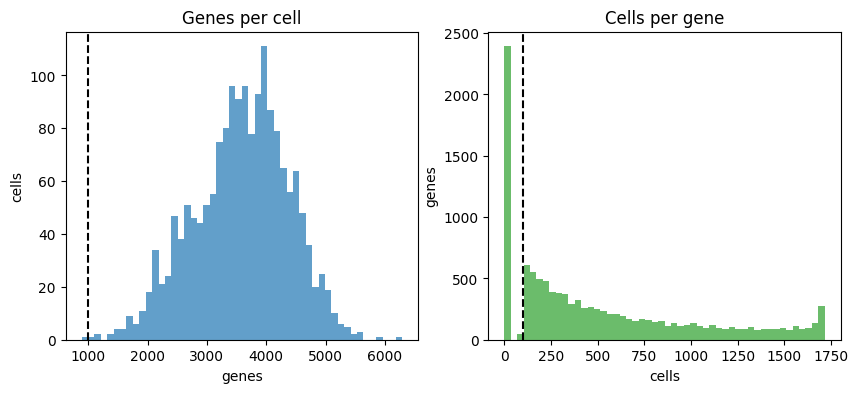

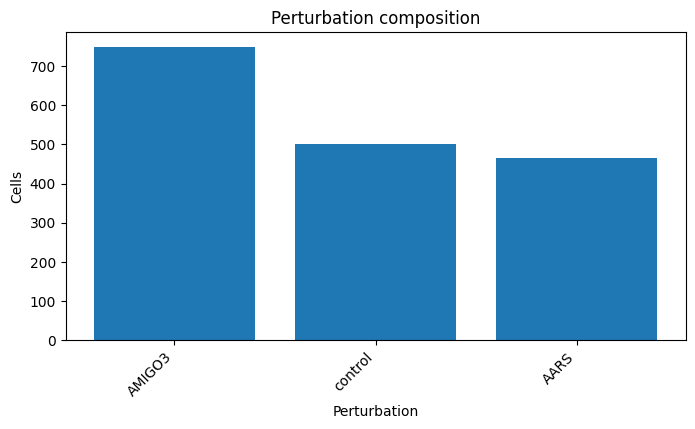

In [4]:
cx.pl.qc_summary(qc, min_genes=1000, min_cells_per_gene=100)
_ = cx.pl.qc_perturbation_counts(data=DATA_PATH, perturbation_column='perturbation', cell_mask=qc.cell_mask)

### A threshold that removes too much

crispyx warns when a filter drops more than half the data, usually a sign of a threshold meant for another dataset. The cell sets a deliberately strict cutoff, and captures the warning to print its message alone.

In [5]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    _ = cx.pp.filter_cells(DATA_PATH, min_genes=4200)

for warning in caught:
    print(f'{warning.category.__name__}: {warning.message}')

[cx] pp.filter_cells: Done  384/1716 cells kept (22%)


### Per-cell metrics, outliers and doublets

A dataset without perturbations (a tissue or a tumour cohort) is filtered on the cells' own metrics instead. `cx.pp.calculate_qc_metrics` writes Scanpy's metrics into the file, here with the mitochondrial genes as a gene set; `cx.pp.mad_outliers` flags cells more than `nmads` median absolute deviations from the median; `cx.pp.scrublet` scores doublets; `cx.pl.violin` shows the metrics, reading only those columns. With several samples, pass the sample column as `groupby` and `batch_key`, so that each sample gets its own thresholds and its own doublet simulation; this screen is one sample.

In [6]:
var = cx.load_var(filtered_path)
var['mt'] = var.index.str.startswith('MT-')
cx.write_var(filtered_path, var)
cx.pp.calculate_qc_metrics(filtered_path, qc_vars=['mt'])

flags = cx.pp.mad_outliers(filtered_path, ['log1p_total_counts', 'pct_counts_mt'], nmads=5)
doublets = cx.pp.scrublet(filtered_path, inplace=False, verbose=False)
print(cx.load_obs(filtered_path)[['total_counts', 'pct_counts_mt']].median().round(1).to_dict())
print('outliers:', flags.sum().to_dict())
print(f"doublets: {int(doublets['predicted_doublet'].sum())} of {len(doublets)} cells")

[cx] pp.calculate_qc_metrics: Reading tutorial_outputs/basics_qc/filtered.h5ad
[cx] pp.calculate_qc_metrics: Done  1715 cells, 9238 genes


{'total_counts': 14514.0, 'pct_counts_mt': 4.9}
outliers: {'log1p_total_counts_low': 4, 'log1p_total_counts_high': 0, 'pct_counts_mt_low': 8, 'pct_counts_mt_high': 18}
doublets: 13 of 1715 cells


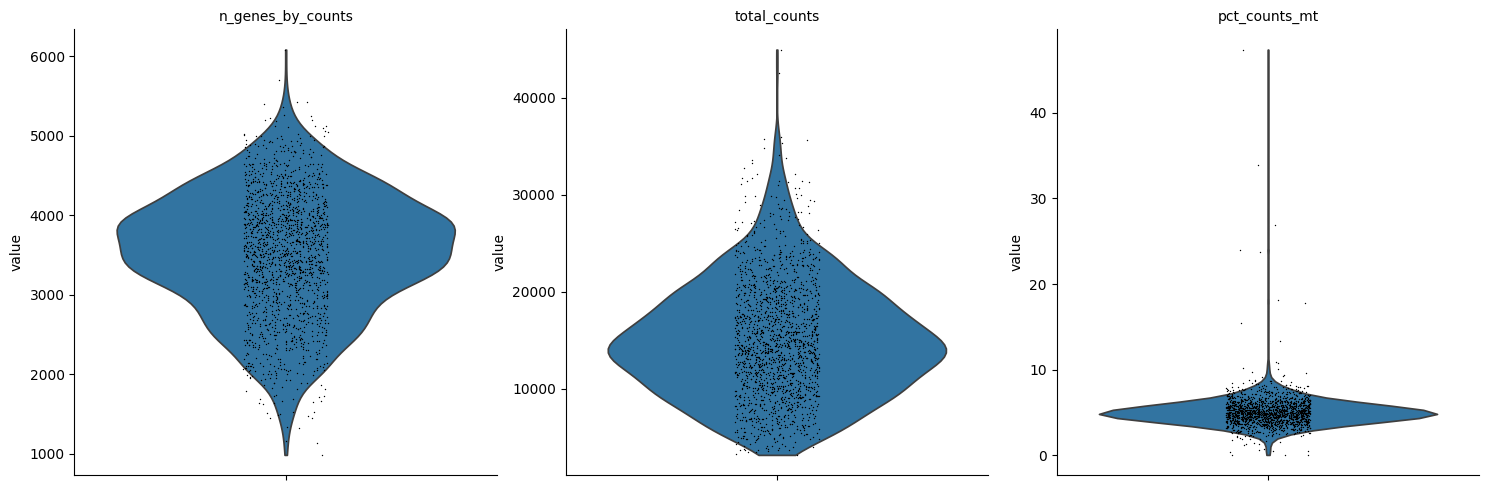

In [7]:
_ = cx.pl.violin(filtered_path, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], multi_panel=True, show=False)

Two questions QC of a screen also asks need guides and unassigned cells, which this dataset does not have: do the non-targeting guides agree with each other (`cx.pp.control_guide_correlation`, plotted by `cx.pl.control_guide_correlation`), and may the unassigned cells join the controls (`cx.pp.compare_controls`)? The [control-checks tutorial](control_checks.ipynb) runs both on a real screen.

## 2. Fewer cells, fewer counts

Two functions reduce a dataset along different axes, both streamed and both before normalisation:

| Function | Decides | Typical use |
|---|---|---|
| `cx.pp.subsample` | which cells stay: `n` or `frac` per stratum of `groupby`; with `unit='batch'`, whole batches are kept or dropped | cap every perturbation at the same number of cells |
| `cx.pp.downsample_counts` | how many counts stay in a cell: thinned to `counts_per_cell` without replacement | equalise sequencing depth between datasets |

In [8]:
# at most 200 cells per perturbation; a smaller group would be kept whole (drop_insufficient=False)
subsampled = cx.pp.subsample(
    filtered_path, n=200, groupby='perturbation', drop_insufficient=False, random_state=0,
    output_path=OUTPUT_DIR / 'subsampled.h5ad',
)
subsampled.obs.load()['perturbation'].value_counts()

[cx] pp.subsample: Done  600/1715 cells kept (35%) across 3 stratum/strata (unit='cell')


perturbation
AARS       200
AMIGO3     200
control    200
Name: count, dtype: int64

In [9]:
depth = np.asarray(qc.filtered.to_memory().X.sum(axis=1)).ravel()
thinned = cx.pp.downsample_counts(
    filtered_path, OUTPUT_DIR / 'downsampled.h5ad', counts_per_cell=int(np.median(depth)), random_state=0,
)
depth_after = np.asarray(thinned.to_memory().X.sum(axis=1)).ravel()
print(f'counts per cell, median and maximum: {np.median(depth):,.0f} and {depth.max():,.0f} '
      f'-> {np.median(depth_after):,.0f} and {depth_after.max():,.0f}')

[cx] pp.downsample_counts: Saving → tutorial_outputs/basics_qc/downsampled.h5ad


[cx] pp.downsample_counts: Done  857/1715 cells thinned to <= 14514 counts
counts per cell, median and maximum: 14,514 and 44,938 -> 14,514 and 14,514


## 3. Normalisation

`cx.pp.normalize_total_log1p` is `scanpy.pp.normalize_total` followed by `scanpy.pp.log1p`, a block of cells at a time. The counts file stays as it is: count models (the NB-GLM in the next notebook) read it, while rank and mean tests read the normalised file.

In [10]:
normalised = cx.pp.normalize_total_log1p(filtered_path, OUTPUT_DIR / 'log1p.h5ad', target_sum=1e4)
print(normalised.shape)

[cx] pp.normalize_total_log1p: Saving → tutorial_outputs/basics_qc/log1p.h5ad
[cx] pp.normalize_total_log1p: Done  1715 cells × 9238 genes
(1715, 9238)


## 4. Variable genes, PCA, neighbours, UMAP, clusters

- **Highly variable genes.** `cx.pp.highly_variable_genes` writes `var['highly_variable']`. In a screen it uses the control cells by default (`cell_mask='control'`), so that the genes chosen describe cell state rather than perturbation effects; `cell_mask=None` uses every cell. `flavor='mean_dispersion'` suits log-normalised data, `'seurat_v3'` raw counts. With several samples, `batch_key` selects genes within each sample and combines them.
- **PCA.** `cx.pp.pca` reads the cells twice (fit, then project) and writes `X_pca` a chunk at a time. It uses the highly variable genes when they are marked, and picks the exact `covariance` method whenever it fits in memory.
- **Neighbours, UMAP and clusters.** `cx.pp.neighbors`, `cx.tl.umap` and `cx.tl.leiden` work on the embedding or the graph, not the matrix.
- **Markers.** `cx.tl.rank_genes_groups` with `reference='rest'` compares each cluster with all other cells.

Results are written into the normalised file. The peak memory of each step is in [Working with large data](../large_data.rst).

In [11]:
cx.pp.highly_variable_genes(normalised, flavor='mean_dispersion', n_top_genes=2000,
                            perturbation_column='perturbation', control_label='control')
cx.pp.pca(normalised, n_comps=20)
cx.pp.neighbors(normalised, n_neighbors=10, show_progress=False)
cx.tl.umap(normalised, min_dist=0.5, spread=1.0)
cx.tl.leiden(normalised, resolution=0.5)

pca = normalised.uns['pca'].load()
print(f"PCA: {pca['method']} on {int(normalised.var['highly_variable'].sum()):,} genes; "
      f"variance explained by the first five components: {pca['variance_ratio'][:5].round(3)}")
print('written to the file:', sorted(normalised.obsm.keys()), sorted(normalised.obsp.keys()))
print('cells per cluster:', normalised.obs['leiden'].value_counts().to_dict())

[cx] pp.highly_variable_genes: Reading tutorial_outputs/basics_qc/log1p.h5ad
[cx] pp.highly_variable_genes: Done  2000/9238 genes marked highly variable


PCA: covariance on 2,000 genes; variance explained by the first five components: [0.051 0.028 0.023 0.014 0.012]
written to the file: ['X_pca', 'X_umap'] ['connectivities', 'distances']
cells per cluster: {'1': 470, '0': 317, '4': 238, '7': 204, '5': 158, '2': 150, '6': 111, '3': 67}


Markers of the clusters: each against all other cells, as Scanpy's `reference='rest'`.

In [12]:
markers = cx.tl.rank_genes_groups(normalised, groupby='leiden', reference='rest', method='wilcoxon',
                                  output_path=OUTPUT_DIR / 'leiden_markers.h5ad', verbose=False)
cx.pl.rank_genes_groups_df(OUTPUT_DIR / 'leiden_markers.h5ad', group='0').head(5)

,names,scores,logfoldchanges,pvals,pvals_adj,pts,pts_rest,group
0,HSP90AB1,14.744119,0.601070,3.356726e-49,6.201886e-46,1.000000,1.000000,0
1,NPM1,12.549148,0.385712,4.018080e-36,4.124335e-33,0.996845,1.000000,0
2,NCL,12.249807,0.784444,1.683968e-34,1.414227e-31,0.990536,0.974964,0
3,HSPD1,11.820948,0.563048,3.042312e-32,2.007492e-29,0.993691,0.992847,0
4,MT-ND5,11.468527,0.494505,1.898626e-30,9.744169e-28,0.996845,0.997139,0


`cx.pl.dotplot` draws the top three markers of each cluster: a dot's size is the share of the cluster's cells that express the gene, its colour their mean. Only those genes are read from the file.

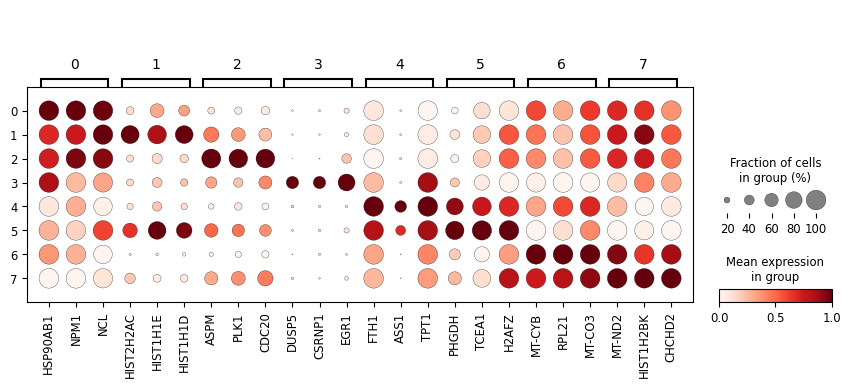

In [13]:
top = {
    cluster: cx.pl.rank_genes_groups_df(OUTPUT_DIR / 'leiden_markers.h5ad', group=cluster)['names'].head(3).tolist()
    for cluster in cx.load_obs(normalised)['leiden'].cat.categories
}
_ = cx.pl.dotplot(normalised, top, 'leiden', standard_scale='var', show=False)

The plotting functions follow Scanpy's and read only what they draw.

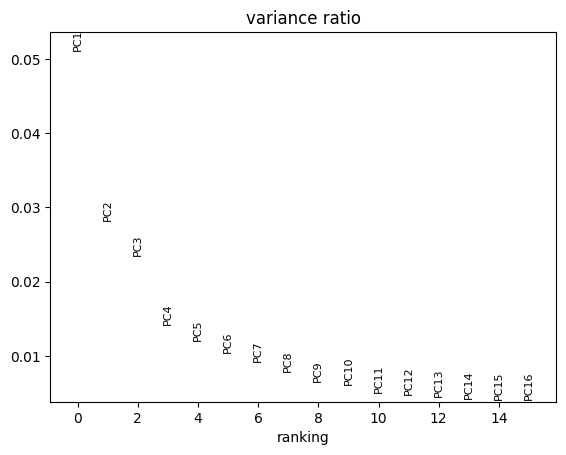

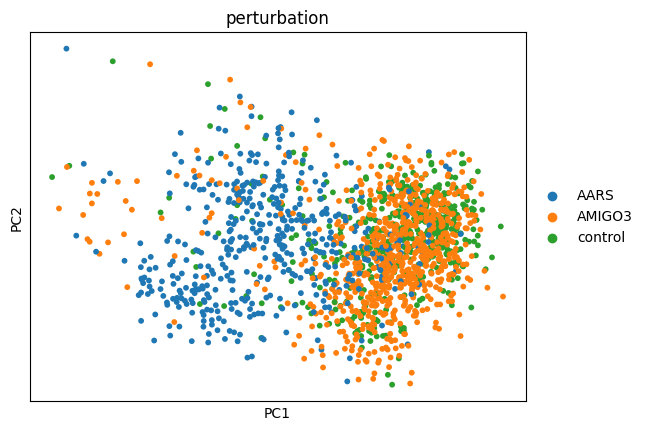

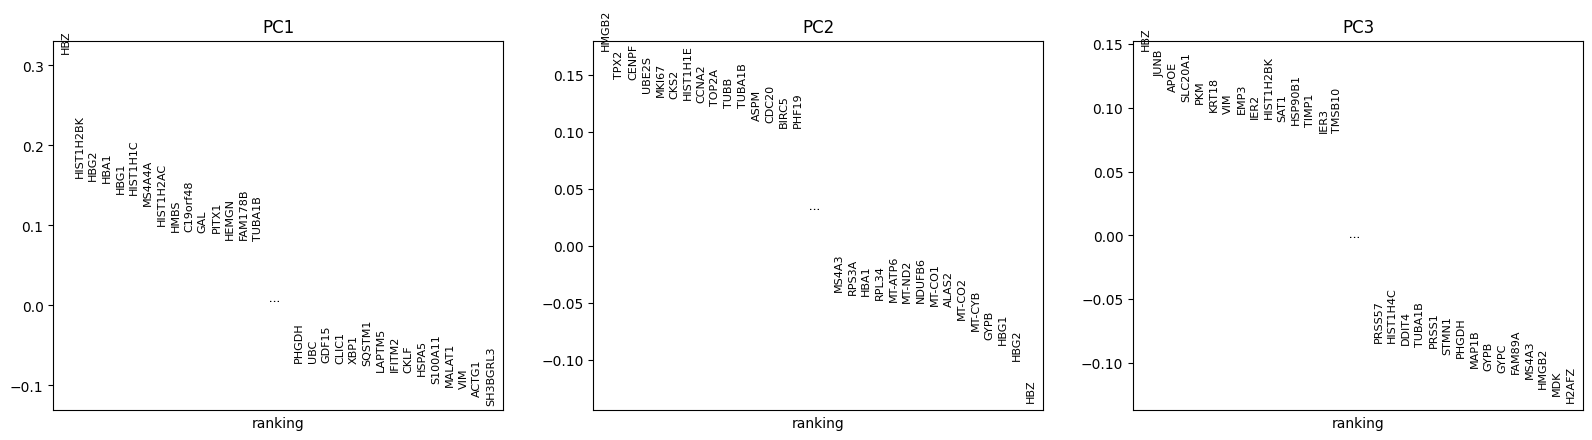

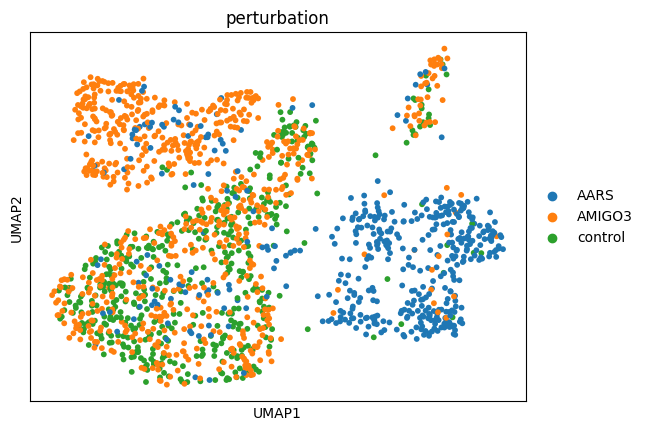

In [14]:
cx.pl.pca_variance_ratio(normalised, n_pcs=15)
cx.pl.pca(normalised, color='perturbation', components='1,2')
cx.pl.pca_loadings(normalised, components=[1, 2, 3])
cx.pl.umap(normalised, color='perturbation')

## 5. Gene-set scores and copy number

`cx.tl.score_genes` scores each cell on a gene set: its mean expression of the set less its mean over reference genes of matched expression, Seurat's method as Scanpy implements it, in two passes over the file. `cx.tl.score_genes_cell_cycle` scores the S and G2/M genes of Tirosh et al. (2016) the same way and assigns a phase. Genes missing from `var` are ignored with a warning; the lists are restricted to the measured genes first, since this file holds a subset of them. The haemoglobin genes score K562's erythroid programme.

In [15]:
S_GENES = ['MCM5', 'PCNA', 'TYMS', 'FEN1', 'MCM2', 'MCM4', 'RRM1', 'UNG', 'GINS2', 'MCM6', 'CDCA7', 'DTL', 'PRIM1',
           'UHRF1', 'CENPU', 'HELLS', 'RFC2', 'RPA2', 'NASP', 'RAD51AP1', 'GMNN', 'WDR76', 'SLBP', 'CCNE2', 'UBR7',
           'POLD3', 'MSH2', 'ATAD2', 'RAD51', 'RRM2', 'CDC45', 'CDC6', 'EXO1', 'TIPIN', 'DSCC1', 'BLM', 'CASP8AP2',
           'USP1', 'CLSPN', 'POLA1', 'CHAF1B', 'BRIP1', 'E2F8']
G2M_GENES = ['HMGB2', 'CDK1', 'NUSAP1', 'UBE2C', 'BIRC5', 'TPX2', 'TOP2A', 'NDC80', 'CKS2', 'NUF2', 'CKS1B', 'MKI67',
             'TMPO', 'CENPF', 'TACC3', 'PIMREG', 'SMC4', 'CCNB2', 'CKAP2L', 'CKAP2', 'AURKB', 'BUB1', 'KIF11', 'ANP32E',
             'TUBB4B', 'GTSE1', 'KIF20B', 'HJURP', 'CDCA3', 'JPT1', 'CDC20', 'TTK', 'CDC25C', 'KIF2C', 'RANGAP1',
             'NCAPD2', 'DLGAP5', 'CDCA2', 'CDCA8', 'ECT2', 'KIF23', 'HMMR', 'AURKA', 'PSRC1', 'ANLN', 'LBR', 'CKAP5',
             'CENPE', 'CTCF', 'NEK2', 'G2E3', 'GAS2L3', 'CBX5', 'CENPA']
measured = set(cx.load_var(normalised).index)
s_genes = [g for g in S_GENES if g in measured]
g2m_genes = [g for g in G2M_GENES if g in measured]
print(f'S genes measured: {len(s_genes)} of {len(S_GENES)}; G2/M genes: {len(g2m_genes)} of {len(G2M_GENES)}')

cx.tl.score_genes_cell_cycle(normalised, s_genes=s_genes, g2m_genes=g2m_genes)
cx.tl.score_genes(normalised, ['HBG1', 'HBG2', 'HBZ', 'HBA1', 'GATA1'], ctrl_size=50, score_name='haemoglobin')
cx.load_obs(normalised).groupby('phase', observed=True)[['S_score', 'G2M_score', 'haemoglobin']].mean().round(3)

S genes measured: 41 of 43; G2/M genes: 50 of 54
[cx] tl.score_genes_cell_cycle: Reading tutorial_outputs/basics_qc/log1p.h5ad
[cx] tl.score_genes_cell_cycle: Done  331 G1, 405 G2M, 979 S
[cx] tl.score_genes: Reading tutorial_outputs/basics_qc/log1p.h5ad
[cx] tl.score_genes: Done  obs['haemoglobin'] for 1,715 cells


,S_score,G2M_score,haemoglobin
phase,,,
G1,-0.125,-0.244,0.571
G2M,0.015,0.250,0.643
S,0.187,-0.070,0.714


Copy-number profiles need each gene's position on the genome, which this file does not carry. With the GTF annotation the reads were aligned to, `cx.pp.genomic_position_from_gtf` adds `chromosome`, `start` and `end` to `var`, and `cx.tl.infercnv` (infercnvpy's method, streamed) writes each cell's profile along the genome, smoothed over windows of 100 genes, to `obsm['X_cnv']`, against reference cells known to be normal:

```python
cx.pp.genomic_position_from_gtf(normalised, 'gencode.v44.annotation.gtf.gz')
cx.tl.infercnv(normalised, reference_key='celltype', reference_cat=['T cell', 'B cell'])
cx.tl.cnv_summary(normalised, 'leiden')        # each cluster's CNV score and mean per chromosome
cx.pl.chromosome_heatmap(normalised, 'leiden')  # cells by cluster x windows by chromosome
```

With several samples, `batch_key='sample_id'` compares each sample with its own reference cells. [Quality control and preprocessing](../quality_control.rst) describes these.

## Functions in this notebook

| Function | What it does | Where |
|---|---|---|
| `cx.pp.filter_cells`, `cx.pp.filter_perturbations`, `cx.pp.filter_genes` | one QC filter each, as a mask | section 1 |
| `cx.pp.qc_summary`, `cx.quality_control_summary` | the three filters in one call, writing the filtered file | 1 |
| `cx.pl.qc_summary`, `cx.pl.qc_perturbation_counts` | QC distributions and cells per perturbation | 1 |
| `cx.pp.calculate_qc_metrics`, `cx.pp.mad_outliers`, `cx.pp.scrublet` | per-cell metrics, outlier flags per sample, doublets per sample | 1 |
| `cx.pl.violin` | distributions of `obs` columns or genes, by group | 1 |
| `cx.pp.compare_controls`, `cx.pp.control_guide_correlation`, `cx.pl.control_guide_correlation` | whether the controls behave alike | [control-checks tutorial](control_checks.ipynb) |
| `cx.pp.subsample` | stratified or cluster sampling of cells | 2 |
| `cx.pp.downsample_counts` | thin each cell's counts to a target | 2 |
| `cx.pp.normalize_total_log1p` | total-count normalisation and log1p | 3 |
| `cx.pp.highly_variable_genes` | variable genes, from the controls by default | 4 |
| `cx.pp.pca`, `cx.pp.neighbors`, `cx.tl.umap`, `cx.tl.leiden` | embedding, neighbour graph and clusters, written to the file | 4 |
| `cx.pl.pca`, `cx.pl.pca_variance_ratio`, `cx.pl.pca_loadings`, `cx.pl.umap` | plots of the embedding | 4 |
| `cx.pl.dotplot` | expression of genes by group, as dots | 4 |
| `cx.tl.score_genes`, `cx.tl.score_genes_cell_cycle` | gene-set scores; cell-cycle scores and phase | 5 |
| `cx.pp.genomic_position_from_gtf`, `cx.tl.infercnv`, `cx.tl.cnv_summary`, `cx.pl.chromosome_heatmap` | gene positions from a GTF; copy-number profiles along the genome, per cluster, as a heatmap | 5 (shown, not run) |

Next: [Effects and differential expression](basics_3_effects_tests.ipynb). More on each step: [Quality control and preprocessing](../quality_control.rst).